# Phase 1 – Statistical Forecasting with the M5 Dataset

## Group Members
- Student 1: `[Bea Nº2170307]`
- Student 2: `[João Coelho Nº2200881]`

## Selected Department-Store
- Department: `FOODS_1`
- Store: `TX_1`

## Objective
This notebook implements **Phase 1** of the project using the **M5 dataset**.  
The goal is to forecast daily sales for all products in one selected **department-store** combination.

The workflow includes:

- data loading and filtering
- exploratory data analysis (EDA)
- train / validation / test split
- baseline models
- ARIMA and ETS models
- ARIMAX with exogenous regressors and calendar features
- evaluation with **MAE**, **RMSE**, and **RMSSE**
- probabilistic forecasts with **95% prediction intervals**

# M5 Forecasting Project – Department Level

Retail demand forecasting is a crucial task for inventory management, supply chain optimization, and strategic planning. Accurate predictions allow companies to anticipate demand fluctuations and allocate resources efficiently.

In this project we analyse a subset of the M5 forecasting dataset, which contains daily sales data for thousands of products across several stores. The objective of this work is to model and forecast the sales behaviour of a selected department within a specific store.

The analysis follows a complete time series forecasting workflow that includes:

- data preprocessing and filtering
- exploratory data analysis (EDA)
- implementation of baseline forecasting models
- comparison with more advanced statistical models
- evaluation using forecasting error metrics
- final testing of the selected model

By comparing different forecasting approaches, we aim to identify the model that best captures the temporal patterns present in the sales data.


## Forecasting Methodology

The dataset is split chronologically to avoid **data leakage**:

| Dataset | Period |
|-------|-------|
| Train | Until 24 Apr 2016 |
| Validation | 25 Apr – 22 May 2016 |
| Test | 23 May – 19 Jun 2016 |

The validation set is used to compare models and select the best one.  
The final model is then retrained on **train + validation** and evaluated on the **test set**.

The forecasting horizon is **28 days**, which corresponds to the standard evaluation window used in the M5 competition.


In [ ]:
!pip install statsforecast pyarrow statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.6/354.6 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 3.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


## 0. Optional Google Drive Persistence

This small setup cell keeps the notebook workflow unchanged while saving CSV outputs to a persistent Google Drive folder when running in Colab. If Google Drive is not available, the notebook falls back to the current working directory.


In [ ]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH = "/content/drive/MyDrive/m5_project"
    os.makedirs(BASE_PATH, exist_ok=True)
    print(f"Google Drive connected. Files will also be saved to: {BASE_PATH}")
except Exception:
    BASE_PATH = "."
    print("Google Drive not available. Using the current working directory.")


Mounted at /content/drive
Google Drive connected. Files will also be saved to: /content/drive/MyDrive/m5_project


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsforecast import StatsForecast

from statsforecast.models import (
    Naive,
    SeasonalNaive,
    HistoricAverage,
    RandomWalkWithDrift,
)

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

## 2. Dataset Description

The dataset used in this project originates from the M5 forecasting competition, which contains daily sales data for thousands of products sold in multiple stores across different states.

Each time series represents the daily number of units sold for a specific product in a specific store. In addition to the sales values, the dataset also includes several explanatory variables such as prices, calendar information, and SNAP indicators.

For this analysis we focus on a subset of the data by selecting a specific department and store. This allows us to analyse a manageable panel of related time series while still preserving the complexity of retail demand patterns.

The main variables used in the analysis include:

- **unique_id**: identifier for each product time series. It represents a specific item sold in a specific store.
- **ds**: date of the observation
- **y**: number of units sold on that day.
- **exogenous variables**: additional features such as prices or calendar-related information

Working with a subset of the dataset allows us to explore forecasting techniques while maintaining computational efficiency.

In [ ]:
base_url = 'https://datasets-nixtla.s3.amazonaws.com'
Y_df = pd.read_parquet(f'{base_url}/m5_y.parquet')
X_df = pd.read_parquet(f'{base_url}/m5_x.parquet')

Y_df["ds"] = pd.to_datetime(Y_df["ds"])
X_df["ds"] = pd.to_datetime(X_df["ds"])

print("Y_df shape:", Y_df.shape)
print("X_df shape:", X_df.shape)

Y_df.head()

Y_df shape: (47649940, 3)
X_df shape: (47649940, 10)


,unique_id,ds,y
0,FOODS_1_001_CA_1,2011-01-29,3.0
1,FOODS_1_001_CA_1,2011-01-30,0.0
2,FOODS_1_001_CA_1,2011-01-31,0.0
3,FOODS_1_001_CA_1,2011-02-01,1.0
4,FOODS_1_001_CA_1,2011-02-02,4.0


## 2. Select Department-Store

To simplify the analysis while maintaining realistic retail dynamics, we focus on a specific department within a single store.

For this project we select:

- **Department:** FOODS_1  
- **Store:** TX_1

This selection produces a panel of related time series corresponding to different products within the same department. Analysing products from the same department helps capture similar demand patterns and seasonal behaviours.

In [ ]:
department = "FOODS_1"
store = "TX_1"

Y_sel = Y_df[
    Y_df["unique_id"].str.contains(department) &
    Y_df["unique_id"].str.contains(store)
].copy()

X_sel = X_df[
    X_df["unique_id"].str.contains(department) &
    X_df["unique_id"].str.contains(store)
].copy()

print("Number of selected series:", Y_sel["unique_id"].nunique())
print("Y_sel shape:", Y_sel.shape)
print("X_sel shape:", X_sel.shape)

Number of selected series: 216
Y_sel shape: (370418, 3)
X_sel shape: (370418, 10)


## 3. Data Splitting Strategy

In time series forecasting, it is essential to preserve the temporal order of observations when splitting the dataset.

The data is divided chronologically into three segments:

- **Training set:** used to estimate the parameters of the forecasting models.
- **Validation set:** used to compare different models and select the best performing one.
- **Test set:** used only once for the final evaluation of the chosen model.

The final 28 days of the dataset are reserved as the test set, while the previous 28 days are used as the validation set. All earlier observations form the training set.

This approach mimics real forecasting conditions, where future values must be predicted using only past information.

In [ ]:
# Final 28 days -> test
test_start = pd.Timestamp("2016-05-23")

# Previous 28 days -> validation
val_start = pd.Timestamp("2016-04-25")
val_end = pd.Timestamp("2016-05-22")

train_main = Y_sel[Y_sel["ds"] < val_start].copy()
val = Y_sel[(Y_sel["ds"] >= val_start) & (Y_sel["ds"] <= val_end)].copy()
train_plus_val = Y_sel[Y_sel["ds"] <= val_end].copy()
test = Y_sel[Y_sel["ds"] >= test_start].copy()

print("Train main:", train_main["ds"].min(), "to", train_main["ds"].max())
print("Validation:", val["ds"].min(), "to", val["ds"].max())
print("Train + validation:", train_plus_val["ds"].min(), "to", train_plus_val["ds"].max())
print("Test:", test["ds"].min(), "to", test["ds"].max())
print("Validation horizon:", val["ds"].nunique())
print("Test horizon:", test["ds"].nunique())

Train main: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Validation: 2016-04-25 00:00:00 to 2016-05-22 00:00:00
Train + validation: 2011-01-29 00:00:00 to 2016-05-22 00:00:00
Test: 2016-05-23 00:00:00 to 2016-06-19 00:00:00
Validation horizon: 28
Test horizon: 28


## 4. Exploratory Data Analysis (EDA)


Before applying forecasting models, it is important to understand the structure and behaviour of the time series.

Exploratory data analysis helps identify important characteristics such as trends, seasonality, variability, and potential anomalies in the data. Understanding these patterns can guide the choice of forecasting models and improve model interpretation.

Several visualisations are used to explore the dataset, including aggregated sales plots, sample time series, and distribution analysis. These plots allow us to observe overall demand dynamics and detect potential seasonal patterns.

In addition, summary statistics and visual inspections help reveal whether sales values are stable over time or if there are significant fluctuations that forecasting models must capture.

To sum up:
- number of time series
- time range
- zero sales proportion
- aggregated sales pattern
- sample individual series
- sales distribution
- weekly seasonality
- monthly heatmap
- autocorrelation
- stationarity on a sample series

In [ ]:
print("Number of series:", Y_sel["unique_id"].nunique())
print("Start date:", Y_sel["ds"].min())
print("End date:", Y_sel["ds"].max())
print("Missing y values:", Y_sel["y"].isna().sum())

zero_pct = (Y_sel["y"] == 0).mean() * 100
print(f"Percentage of zero sales observations: {zero_pct:.2f}%")

Number of series: 216
Start date: 2011-01-29 00:00:00
End date: 2016-06-19 00:00:00
Missing y values: 0
Percentage of zero sales observations: 63.46%


### 4.1 Aggregated Sales Over Time

The aggregated sales plot shows the total number of units sold across all selected products over time.

By analysing the aggregated series, we can observe general demand trends and detect potential seasonal patterns or unusual fluctuations. Aggregation also reduces noise from individual product series and highlights the overall behaviour of the department.

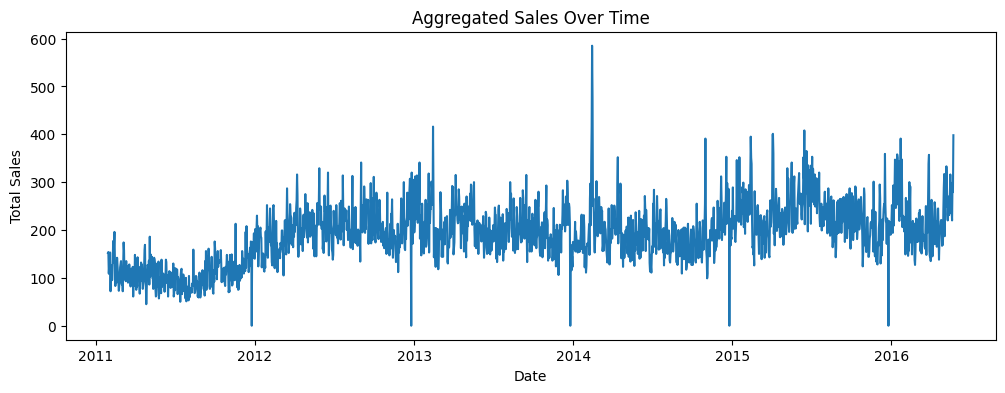

In [ ]:
agg_sales = train_plus_val.groupby("ds")["y"].sum()

plt.figure(figsize=(12, 4))
plt.plot(agg_sales)
plt.title("Aggregated Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

### 4.2 Sample Individual Time Series

To better understand the variability between products, we visualise a few individual time series.

Each series represents the daily sales of a specific product. Comparing multiple products allows us to observe differences in demand patterns, sales volatility, and possible seasonal effects across items.

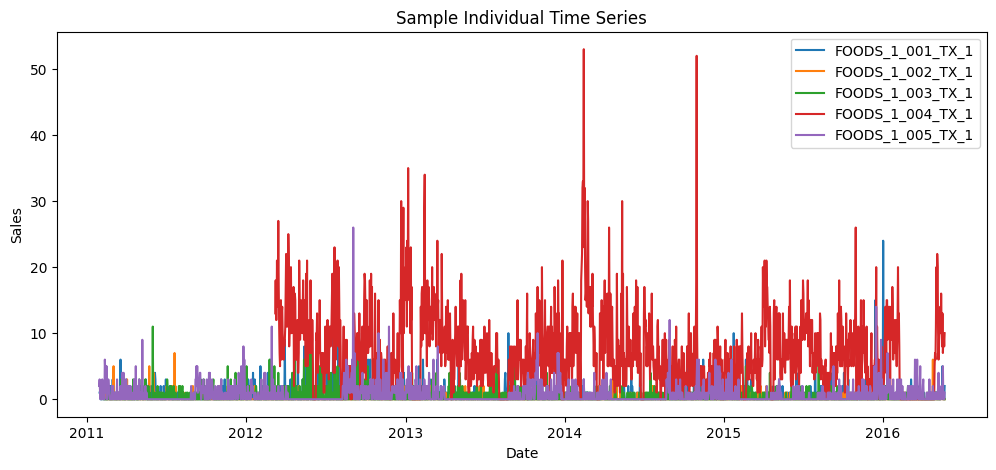

In [ ]:
sample_ids = train_plus_val["unique_id"].drop_duplicates().iloc[:5].tolist()

plt.figure(figsize=(12, 5))
for uid in sample_ids:
    s = train_plus_val[train_plus_val["unique_id"] == uid]
    plt.plot(s["ds"], s["y"], label=uid)

plt.title("Sample Individual Time Series")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

### 4.3 Sales Distribution

The distribution of sales values provides insight into the variability and scale of the observations.

Retail sales data often exhibits a skewed distribution, where many observations correspond to low sales values while occasional peaks represent higher demand periods. Understanding the distribution helps interpret the difficulty of the forecasting task and the presence of potential outliers.

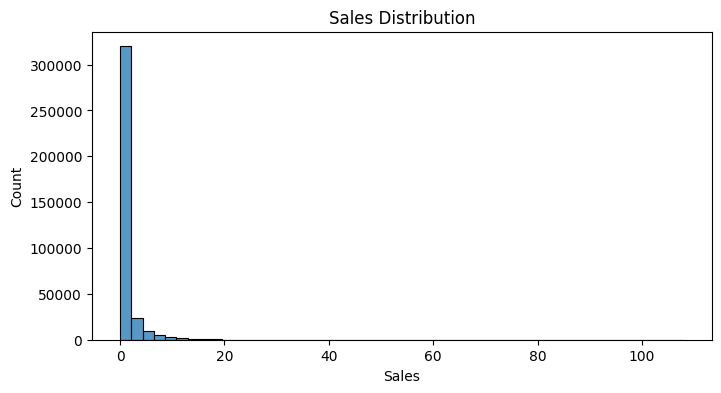

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(train_plus_val["y"], bins=50)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.show()

### 4.4 Weekly Seasonality

Consumer shopping behaviour often follows weekly patterns. For example, sales may increase during weekends or decrease on certain weekdays.

By analysing average sales for each day of the week, we can identify whether weekly seasonality is present in the data. If strong weekly patterns exist, forecasting models that incorporate seasonal components may achieve better performance.

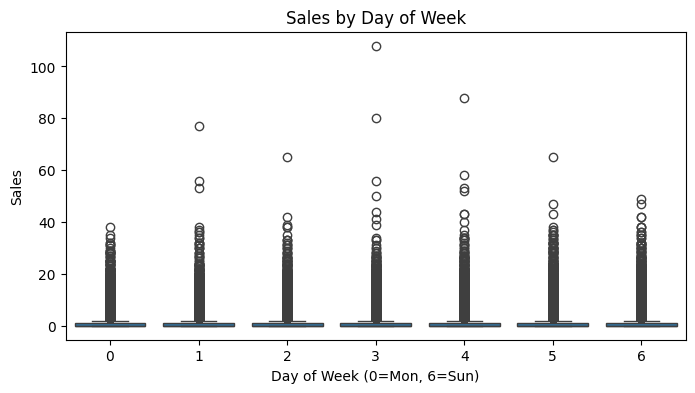

In [ ]:
eda_df = train_plus_val.copy()
eda_df["day_of_week"] = eda_df["ds"].dt.dayofweek

plt.figure(figsize=(8, 4))
sns.boxplot(data=eda_df, x="day_of_week", y="y")
plt.title("Sales by Day of Week")
plt.xlabel("Day of Week (0=Mon, 6=Sun)")
plt.ylabel("Sales")
plt.show()

### 4.5 Monthly Heatmap

The heatmap visualises average sales across months and years.

This representation helps detect long-term seasonal patterns or recurring demand cycles. Retail sales are frequently influenced by holidays, seasonal shopping habits, and promotional events, which may appear as visible patterns in this visualization.

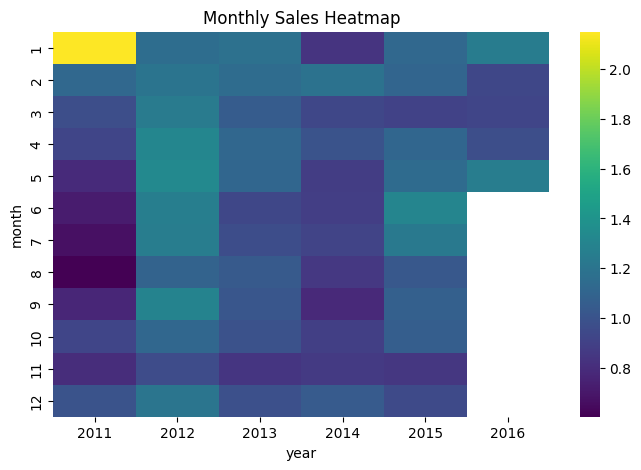

In [ ]:
heat_df = train_plus_val.copy()
heat_df["year"] = heat_df["ds"].dt.year
heat_df["month"] = heat_df["ds"].dt.month

pivot = heat_df.pivot_table(values="y", index="month", columns="year", aggfunc="mean")

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, cmap="viridis")
plt.title("Monthly Sales Heatmap")
plt.show()

### 4.6 Autocorrelation and Stationarity

Autocorrelation analysis measures how strongly current sales values are related to past observations.

The autocorrelation function (ACF) helps identify temporal dependencies within the series, indicating whether previous values contain useful information for predicting future sales.

In addition, stationarity tests are applied to evaluate whether the statistical properties of the series remain stable over time. Many forecasting models assume stationarity, so this step helps determine whether transformations such as differencing may be required.

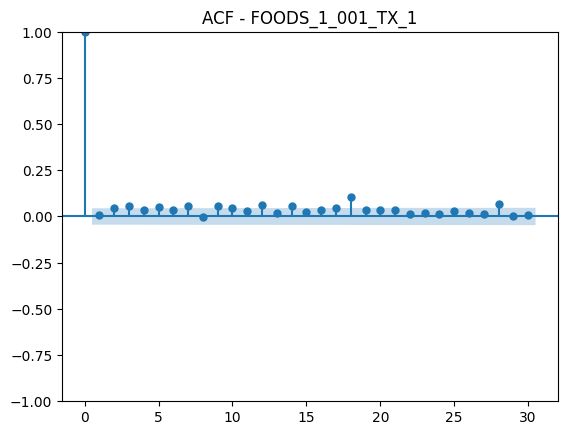

ADF Statistic: -7.064864155842239
p-value: 5.111527586238421e-10


In [ ]:
sample_uid = sample_ids[0]
sample_series = train_plus_val[train_plus_val["unique_id"] == sample_uid]["y"]

plot_acf(sample_series, lags=30)
plt.title(f"ACF - {sample_uid}")
plt.show()

adf_stat, p_value, *_ = adfuller(sample_series.dropna())
print("ADF Statistic:", adf_stat)
print("p-value:", p_value)

In [ ]:

result = adfuller(sample_series)

print(f"ADF Statistic: {result[0]}")
print(f"p-value: {result[1]}")

if result[1] > 0.05:
    print("⚠️ Series is probably NOT stationary")
else:
    print(" Series is stationary")

ADF Statistic: -7.064864155842239
p-value: 5.111527586238421e-10
 Series is stationary


### 4.7 Key Insights from EDA

The exploratory analysis revealed several important patterns in the data:

- Retail demand exhibits strong weekly seasonality.
- Many products show intermittent demand with frequent zero sales.
- Sales distributions are highly skewed.
- Autocorrelation suggests that past values are useful predictors for forecasting models.

These insights justify the use of statistical time series models such as ARIMA and ETS.

## 5. Evaluation Metrics

To compare the performance of different forecasting models, several error metrics are used.

The main evaluation metrics include:

- **MAE (Mean Absolute Error):** measures the average magnitude of prediction errors.
- **RMSE (Root Mean Squared Error):** penalises larger errors more heavily due to the squared term.
- **RMSSE (Root Mean Squared Scaled Error):** a scale-independent metric widely used in the M5 competition.

These metrics provide a quantitative way to assess forecasting accuracy and determine which models perform best.

The Root Mean Squared Scaled Error (RMSSE) is the main evaluation metric used in the M5 Forecasting Competition.

Unlike traditional metrics such as RMSE or MAE, RMSSE scales the prediction error relative to a naive seasonal forecast. This allows a fair comparison between time series with very different sales magnitudes.

In retail datasets, where some products sell thousands of units and others sell only a few, RMSSE is particularly useful because it normalizes the error across different series.

In [ ]:
def mae(actual, pred):
    return mean_absolute_error(actual, pred)

def rmse(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))

def rmsse_per_series(train_series, actual, pred):
    train_series = np.asarray(train_series, dtype=float)
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)

    scale = np.mean(np.diff(train_series) ** 2)
    if scale == 0 or np.isnan(scale):
        return np.nan

    mse = np.mean((actual - pred) ** 2)
    return np.sqrt(mse / scale)

def evaluate_panel(train_df, actual_df, pred_df, model_col):
    merged = actual_df.merge(
        pred_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="left"
    )

    mae_global = mae(merged["y"], merged[model_col])
    rmse_global = rmse(merged["y"], merged[model_col])

    rmsse_list = []
    for uid in merged["unique_id"].unique():
        train_series = train_df.loc[train_df["unique_id"] == uid, "y"]
        actual_series = merged.loc[merged["unique_id"] == uid, "y"]
        pred_series = merged.loc[merged["unique_id"] == uid, model_col]
        score = rmsse_per_series(train_series, actual_series, pred_series)
        rmsse_list.append(score)

    rmsse_mean = np.nanmean(rmsse_list)
    return mae_global, rmse_global, rmsse_mean

## 6. Baseline and Statistical Models on the Validation Set

Baseline forecasting models provide simple reference points that allow us to evaluate whether more advanced models actually improve forecasting accuracy.

The models considered include:

- **Naive model**, which predicts the next value as the last observed value.
- **Seasonal Naive**, which repeats the value from the same period in the previous season.
- **Historical Average**, which predicts future values using the mean of past observations.
- **Random Walk with Drift**, which extends the naive approach by incorporating a constant trend component.

These models establish a performance benchmark that more complex statistical models should outperform.

In [ ]:
from statsforecast.models import (
    Naive,
    SeasonalNaive,
    HistoricAverage,
    RandomWalkWithDrift,
)

models = [
    Naive(),
    SeasonalNaive(season_length=7),
    HistoricAverage(),
    RandomWalkWithDrift(),
]

sf_val = StatsForecast(
    models=models,
    freq="D",
    n_jobs=-1
)

sf_val.fit(train_main)
fcst_val = sf_val.predict(h=28)

fcst_val_reset = fcst_val.reset_index()
fcst_val_reset.to_csv("baseline_forecasts_val.csv", index=False)
fcst_val_reset.to_csv(f"{BASE_PATH}/baseline_forecasts_val.csv", index=False)
fcst_val.head()

,unique_id,ds,Naive,SeasonalNaive,HistoricAverage,RWD
0,FOODS_1_001_TX_1,2016-04-25,0.0,0.0,0.585251,-0.000523
1,FOODS_1_001_TX_1,2016-04-26,0.0,0.0,0.585251,-0.001047
2,FOODS_1_001_TX_1,2016-04-27,0.0,0.0,0.585251,-0.001570
3,FOODS_1_001_TX_1,2016-04-28,0.0,0.0,0.585251,-0.002093
4,FOODS_1_001_TX_1,2016-04-29,0.0,0.0,0.585251,-0.002616


In [ ]:
model_cols = [
    "Naive",
    "SeasonalNaive",
    "HistoricAverage",
    "RWD",
]

val_results = []

for m in model_cols:
    mae_v, rmse_v, rmsse_v = evaluate_panel(train_main, val, fcst_val, m)
    val_results.append({
        "Model": m,
        "MAE": mae_v,
        "RMSE": rmse_v,
        "RMSSE": rmsse_v
    })

val_results_df = pd.DataFrame(val_results).sort_values("RMSSE").reset_index(drop=True)
val_results_df


,Model,MAE,RMSE,RMSSE
0,HistoricAverage,1.098873,1.881901,0.763119
1,Naive,1.258598,2.439411,0.940938
2,RWD,1.272988,2.453267,0.946122
3,SeasonalNaive,1.226852,2.438055,0.955998


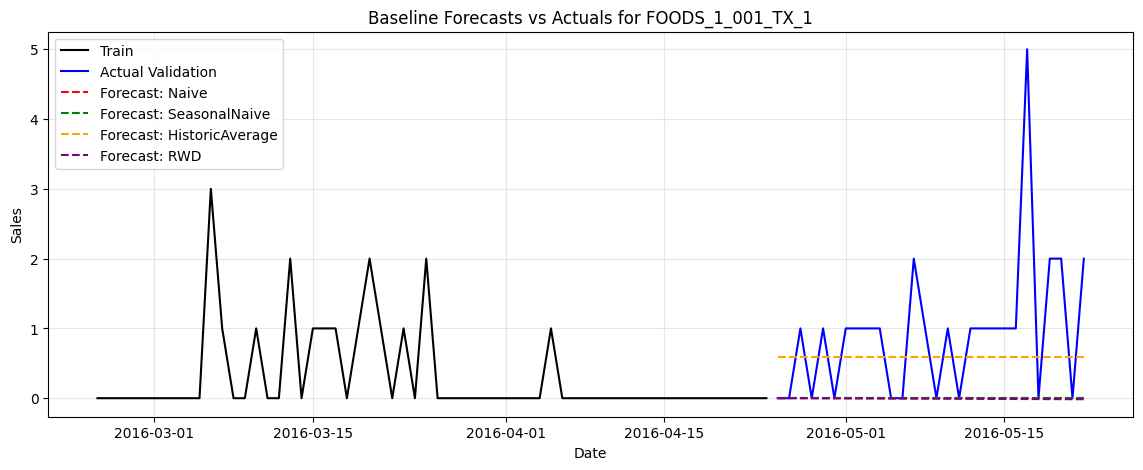

In [ ]:

sample_id = val["unique_id"].iloc[0]

train_plot = train_main[train_main["unique_id"] == sample_id].tail(60) # Últimos 60 dias de treino
val_plot = val[val["unique_id"] == sample_id]
fcst_plot = fcst_val[fcst_val["unique_id"] == sample_id]

plt.figure(figsize=(14, 5))
plt.plot(train_plot["ds"], train_plot["y"], label="Train", color="black")
plt.plot(val_plot["ds"], val_plot["y"], label="Actual Validation", color="blue")

colors = ["red", "green", "orange", "purple"]
for i, m in enumerate(model_cols):
    plt.plot(fcst_plot["ds"], fcst_plot[m], label=f"Forecast: {m}", color=colors[i], linestyle="--")

plt.title(f"Baseline Forecasts vs Actuals for {sample_id}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Export baseline leaderboard for the AutoARIMA / ETS notebooks
baseline_metrics = val_results_df[["Model", "MAE", "RMSE", "RMSSE"]].copy()
baseline_metrics = baseline_metrics.sort_values("RMSSE").reset_index(drop=True)

display(baseline_metrics)
baseline_metrics.to_csv("baseline_metrics.csv", index=False)
baseline_metrics.to_csv(f"{BASE_PATH}/baseline_metrics.csv", index=False)
print("Ficheiro 'baseline_metrics.csv' guardado com sucesso!")
print(f"Também guardado em: {BASE_PATH}/baseline_metrics.csv")


,Model,MAE,RMSE,RMSSE
0,HistoricAverage,1.098873,1.881901,0.763119
1,Naive,1.258598,2.439411,0.940938
2,RWD,1.272988,2.453267,0.946122
3,SeasonalNaive,1.226852,2.438055,0.955998


Ficheiro 'baseline_metrics.csv' guardado com sucesso!
Também guardado em: /content/drive/MyDrive/m5_project/baseline_metrics.csv


## 7. Baseline Model Performance Analysis

The results show that the Historic Average model achieves the best performance among the baselines, followed by the Naive and Drift-based approaches.

This suggests that, for this department-store panel, the demand exhibits a relatively stable level over time, with limited short-term variability that can be captured by simple averaging.

On the other hand, the weaker performance of the Seasonal Naive model indicates that weekly seasonality alone is not sufficient to explain the behavior of the series. This highlights the presence of additional dynamics beyond simple periodic patterns.

Overall, the baseline results confirm that while simple models capture part of the signal, they are insufficient to fully explain the complexity of retail demand, motivating the use of more advanced statistical models in the next stages.

## 8. Transition to Advanced Models

The baseline analysis reveals three important characteristics of the data:
- the presence of temporal dependence,
- partial but not dominant seasonality,
- and relatively stable demand levels.

These observations motivate the use of autoregressive models such as AutoARIMA, which are designed to capture both autocorrelation and non-stationarity in time series data.

The next notebook builds on this foundation by introducing statistical models that can better exploit these patterns.

In [ ]:

# EXPORT PARA AUTOARIMA (COLAB)

final_df = Y_sel[["unique_id", "ds", "y"]].copy()

final_df["ds"] = pd.to_datetime(final_df["ds"])

final_df = final_df.sort_values(["unique_id", "ds"])

final_df.to_csv("m5_clean.csv", index=False)
final_df.to_csv(f"{BASE_PATH}/m5_clean.csv", index=False)

print("CSV exportado: m5_clean.csv")
print(f"Também guardado em: {BASE_PATH}/m5_clean.csv")

CSV exportado: m5_clean.csv
Também guardado em: /content/drive/MyDrive/m5_project/m5_clean.csv


In [ ]:
# Optional manual download
from google.colab import files
files.download(f"{BASE_PATH}/baseline_metrics.csv" if BASE_PATH != "." else "baseline_metrics.csv")
# Optional: download the cleaned panel used by the AutoARIMA notebook
# files.download(f"{BASE_PATH}/m5_clean.csv" if BASE_PATH != "." else "m5_clean.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>